# Adaptive-width conformal prediction

The [split conformal tutorial](../split-conformal/README.md) used one interval width for every input. Here we fit a second model that estimates where prediction errors tend to be larger. We compare both methods using the same point predictor, calibration observations, and test responses.

## 1. Give each input its own scale

Let $\widehat f(x)$ predict the response at input $x$. Let $\widehat s(x)>0$ estimate the typical size of a prediction error there. A scale can describe the *relative* size of errors across inputs. Its units or overall multiplier are absorbed by calibration.

We fit $\widehat f$ on the first training subset. On a second training subset, we fit a straight line to the log absolute residuals. For fitted coefficients $\widehat a,\widehat b$, the scale is

$$
\widehat s(x)=\exp(\widehat a+\widehat b x).
$$

The exponential keeps the scale positive. Before taking logs, the code floors residual magnitudes at $10^{-6}$. This fitted scale summarizes residual size and may reflect both noise and mean prediction error. Both fits are frozen before calibration.

## 2. Calibrate the normalized residuals

On the calibration set, compute an absolute error $R_i$ and a normalized score $S_i$ for each pair $(X_i,Y_i)$.

$$
R_i=\bigl|Y_i-\widehat f(X_i)\bigr|,
\qquad
S_i=\frac{R_i}{\widehat s(X_i)},
\qquad i=1,\dots,m.
$$

For $m$ calibration observations and target coverage $1-\alpha$, use the rank

$$
k=\left\lceil(m+1)(1-\alpha)\right\rceil.
$$

The ceiling rounds up. Let $q_R=R_{(k)}$ and $q_S=S_{(k)}$, where $(k)$ denotes the $k$th smallest value in each respective score list. When $k=m+1$, set both thresholds to $+\infty$. For $m=199$ and 90% coverage, use rank $180$.

## 3. Convert back to response units

The constant and adaptive prediction intervals are

$$
C_{\mathrm{constant}}(x)
=\left[\widehat f(x)-q_R,\ \widehat f(x)+q_R\right],
$$

$$
C_{\mathrm{adaptive}}(x)
=\left[\widehat f(x)-q_S\widehat s(x),\
       \widehat f(x)+q_S\widehat s(x)\right].
$$

The normalized score divides by the scale. The interval radius multiplies by it. For example, with $\widehat f(x)=3$, $\widehat s(x)=0.4$, and $q_S=1.5$, the radius is $0.6$ and the interval is $[2.4,3.6]$.

Multiplying every fitted scale by a constant $c>0$ divides every normalized calibration score and $q_S$ by $c$. The final radius stays the same.

## 4. Interpret the guarantee

Assume the calibration observations and one future pair are exchangeable conditional on the two training subsets. Independent observations from the same distribution meet this assumption. The same frozen score function applies to every calibration observation and to the future pair, so the scores are exchangeable as well. With no ties, the rank of the future score among the $m+1$ scores is uniform. With ties, including scores equal to the threshold preserves the lower bound.

For either interval rule $C$, the guarantee is

$$
\Pr\!\left\{Y_{\mathrm{new}}\in C(X_{\mathrm{new}})\right\}
\ge 1-\alpha.
$$

The probability averages over the calibration data and the future pair, with the fitted models held fixed. It is a marginal guarantee for one future response. Coverage within a fixed input region can differ from the target even when this guarantee holds.

## 5. Compare both methods on the same data

Generate $X$ uniformly on $[-1,1]$ and an independent standard normal error $\varepsilon$. Set

$$
Y=0.5+X+0.4\exp(X)\,\varepsilon.
$$

The noise standard deviation increases with $X$. Each of the 400 runs generates 160 observations to fit the mean, 240 to fit the scale, 199 for calibration, and 1,500 for evaluation. For a region $A$, observed coverage is

$$
\widehat c_A
=\frac{\sum_j \mathbf{1}\!\left\{X_j\in A,\ Y_j\in C_j(X_j)\right\}}
       {\sum_j \mathbf{1}\!\left\{X_j\in A\right\}}.
$$

Here $j$ indexes the pooled test responses and $C_j$ is the interval from the run that produced test response $j$. Mean width averages $U_j-L_j$ over those same test inputs, where $L_j$ and $U_j$ are the lower and upper endpoints. Test responses within a run share the fitted models and calibration data. Treat the 400 runs as the independent units if you want to quantify simulation uncertainty.


400 independent runs with 1500 test points each
Method            Overall coverage   Mean width
Constant width              89.84%        1.786
Adaptive width              90.02%        1.579

Input region      Constant cov.  Adaptive cov.   Constant width   Adaptive width
[-1, -0.5)               99.99%         89.92%            1.786            0.651
[-0.5, 0)                99.04%         90.41%            1.786            1.062
[0, 0.5)                 90.29%         90.05%            1.785            1.740
[0.5, 1)                 70.08%         89.70%            1.786            2.860


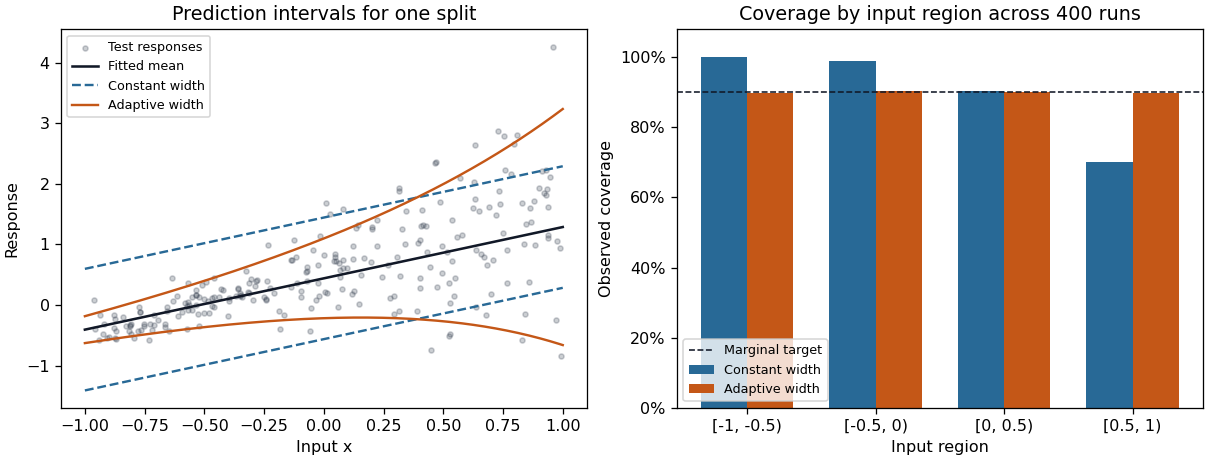

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

TARGET_PERCENT = 90
N_CALIBRATION = 199
REGION_EDGES = np.linspace(-1, 1, 5)


def design(x):
    return np.column_stack([np.ones(x.size), x])


def sample(rng, n):
    x = rng.uniform(-1, 1, n)
    noise_sd = 0.4 * np.exp(x)
    y = 0.5 + x + noise_sd * rng.normal(size=n)
    return x, y


def calibration_threshold(scores, target_percent):
    # Integer ceiling keeps exact ranks for whole-number coverage percentages.
    rank = ((scores.size + 1) * target_percent + 99) // 100
    if rank > scores.size:
        return np.inf
    return np.sort(scores)[rank - 1]


def fit_and_calibrate(rng):
    x_fit, y_fit = sample(rng, 160)
    mean_coef = np.linalg.lstsq(design(x_fit), y_fit, rcond=None)[0]

    x_scale, y_scale = sample(rng, 240)
    abs_error = np.abs(y_scale - design(x_scale) @ mean_coef)
    log_error = np.log(np.maximum(abs_error, 1e-6))
    scale_coef = np.linalg.lstsq(design(x_scale), log_error, rcond=None)[0]

    x_cal, y_cal = sample(rng, N_CALIBRATION)
    cal_error = np.abs(y_cal - design(x_cal) @ mean_coef)
    cal_scale = np.exp(design(x_cal) @ scale_coef)
    constant_q = calibration_threshold(cal_error, TARGET_PERCENT)
    scaled_q = calibration_threshold(cal_error / cal_scale, TARGET_PERCENT)
    return mean_coef, scale_coef, constant_q, scaled_q


def predict(x, fit):
    mean_coef, scale_coef, constant_q, scaled_q = fit
    center = design(x) @ mean_coef
    constant_radius = np.full(x.size, constant_q)
    adaptive_radius = scaled_q * np.exp(design(x) @ scale_coef)
    return center, np.vstack([constant_radius, adaptive_radius])


def main():
    # Independent random streams for the example plot and repeated experiment.
    plot_seed, experiment_seed = np.random.SeedSequence(81025).spawn(2)
    plot_rng = np.random.default_rng(plot_seed)
    fit = fit_and_calibrate(plot_rng)
    x_plot, y_plot = sample(plot_rng, 250)
    grid = np.linspace(-1, 1, 300)
    center, radii = predict(grid, fit)

    rng = np.random.default_rng(experiment_seed)
    repetitions, n_test = 400, 1500
    hits = np.zeros((2, 4), dtype=int)
    widths = np.zeros((2, 4))
    counts = np.zeros(4, dtype=int)
    for _ in range(repetitions):
        fitted = fit_and_calibrate(rng)
        x, y = sample(rng, n_test)
        test_center, test_radii = predict(x, fitted)
        covered = np.abs(y - test_center) <= test_radii
        for j, (left, right) in enumerate(zip(REGION_EDGES[:-1], REGION_EDGES[1:])):
            in_region = (left <= x) & (x < right)
            counts[j] += in_region.sum()
            hits[:, j] += covered[:, in_region].sum(axis=1)
            widths[:, j] += (2 * test_radii[:, in_region]).sum(axis=1)

    coverage_by_region = hits / counts
    width_by_region = widths / counts
    overall_coverage = hits.sum(axis=1) / counts.sum()
    overall_width = widths.sum(axis=1) / counts.sum()

    labels = ["Constant width", "Adaptive width"]
    print(f"{repetitions} independent runs with {n_test} test points each")
    print(f"{'Method':<16}{'Overall coverage':>18}{'Mean width':>13}")
    for label, coverage, width in zip(labels, overall_coverage, overall_width):
        print(f"{label:<16}{coverage:>18.2%}{width:>13.3f}")
    print()
    print(f"{'Input region':<16}{'Constant cov.':>15}{'Adaptive cov.':>15}"
          f"{'Constant width':>17}{'Adaptive width':>17}")
    region_labels = ["[-1, -0.5)", "[-0.5, 0)", "[0, 0.5)", "[0.5, 1)"]
    for j, region in enumerate(region_labels):
        print(f"{region:<16}{coverage_by_region[0, j]:>15.2%}"
              f"{coverage_by_region[1, j]:>15.2%}{width_by_region[0, j]:>17.3f}"
              f"{width_by_region[1, j]:>17.3f}")

    blue, orange = "#286996", "#c45717"
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), layout="constrained")
    ax = axes[0]
    ax.scatter(x_plot, y_plot, color="#374151", s=10, alpha=0.25, label="Test responses")
    ax.plot(grid, center, color="#111827", linewidth=1.6, label="Fitted mean")
    ax.plot(grid, center + radii[0], "--", color=blue, label=labels[0])
    ax.plot(grid, center - radii[0], "--", color=blue)
    ax.plot(grid, center + radii[1], color=orange, label=labels[1])
    ax.plot(grid, center - radii[1], color=orange)
    ax.set(title="Prediction intervals for one split", xlabel="Input x", ylabel="Response")
    ax.legend(fontsize=8)

    ax = axes[1]
    positions = np.arange(len(region_labels))
    ax.bar(positions - 0.18, coverage_by_region[0], 0.36, color=blue, label=labels[0])
    ax.bar(positions + 0.18, coverage_by_region[1], 0.36, color=orange, label=labels[1])
    ax.axhline(TARGET_PERCENT / 100, color="#111827", linestyle="--", linewidth=1,
               label="Marginal target")
    ax.set(xticks=positions, xticklabels=region_labels, ylim=(0, 1.08),
           title="Coverage by input region across 400 runs", xlabel="Input region",
           ylabel="Observed coverage")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.legend(loc="lower left", fontsize=8)
    plt.show()


if __name__ == "__main__":
    main()


## 6. What changed?

In this simulation, both methods gave close to 90% overall coverage. With constant width, coverage fell to about 70% in the highest noise region. The adaptive method brought all four regional estimates within about half a percentage point of 90%. It used narrower intervals in quiet regions and wider ones in noisy regions. Its mean width was about 12% smaller in this example.

The scale model can help when it captures how errors vary across inputs. The regional estimates and width savings are specific to this simulation. A different noise pattern or a poor scale fit can change both results.

Try replacing the increasing noise scale in the generator with a constant, then compare regional coverage and mean width again. Next try a U-shaped noise scale and see whether a log-linear scale model is flexible enough.

## Further reading

- Lei, G’Sell, Rinaldo, Tibshirani, and Wasserman (2018), *Distribution-Free Predictive Inference for Regression*. [Journal of the American Statistical Association](https://doi.org/10.1080/01621459.2017.1307116).
- Oliveira, Orenstein, Ramos, and Romano (2024), *Split Conformal Prediction and Non-Exchangeable Data*. [Journal of Machine Learning Research](https://jmlr.org/papers/v25/23-1553.html).
